## **K-Means and Hierarchical Clustering: MCQ Revision Notebook**

### **Learning objectives**
- Explain unsupervised clustering and distance-based grouping.
- Prepare and standardise customer data.
- Apply K-Means and agglomerative hierarchical clustering.
- Use the elbow method, silhouette score and Davies–Bouldin index.
- Interpret cluster profiles and practise examination-style MCQs.

We use the Mall Customers dataset. `CustomerID` is an identifier, so it is excluded from clustering. `Gender` is retained for optional descriptive profiling but is not used as a distance feature.

## **1. Import libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)


## **2. Plotting helper**

This uses the consistent `style_plot()` format for notebook visualisations.

In [2]:
def style_plot(
    ax, title=None, xlabel=None, ylabel=None,
    title_fontsize=14, label_fontsize=11,
    remove_spines=True, grid=True, legend=True
):
    if title:
        ax.set_title(title, fontsize=title_fontsize,
                     fontweight="bold", pad=15)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=label_fontsize)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=label_fontsize)
    if grid:
        ax.grid(True, linestyle="--", alpha=0.4,
                linewidth=0.3, color="gray")
    if legend and ax.get_legend() is not None:
        ax.legend(fontsize=9)
    if remove_spines:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        for spine in ax.spines.values():
            spine.set_linewidth(1.2)
    ax.set_facecolor("whitesmoke")
    return ax


## **3. Load the Mall Customers data**

In [4]:
url = "https://cdn.alx-ai-tools.com/marimo/v2/data/Data/unsupervised_sprint/mall_customers.csv"

data = pd.read_csv(url, index_col=0)
display(data.head())
print("Shape:", data.shape)


,Genre,Age,Annual_Income_(k$),Spending_Score
CustomerID,,,,
1,Male,19,15,39
2,Male,21,15,81
3,Female,20,16,6
4,Female,23,16,77
5,Female,31,17,40


Shape: (200, 4)


#### **Question 1**

> Print the descriptive statistics of our dataset. True or false. The Spending_Score is a number from 1 - 50.

In [5]:
statistics = data.describe().T
statistics["range"] = statistics["max"] - statistics["min"]

display(statistics)

,count,mean,std,min,25%,50%,75%,max,range
Age,200.000,38.850,13.969,18.000,28.750,36.000,49.000,70.000,52.000
Annual_Income_(k$),200.000,60.560,26.265,15.000,41.500,61.500,78.000,137.000,122.000
Spending_Score,200.000,50.200,25.824,1.000,34.750,50.000,73.000,99.000,98.000


#### **Question 2**

> What is the total number of observations in this dataset?

In [ ]:
display(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Genre               200 non-null    str  
 1   Age                 200 non-null    int64
 2   Annual_Income_(k$)  200 non-null    int64
 3   Spending_Score      200 non-null    int64
dtypes: int64(3), str(1)
memory usage: 6.4 KB


None

#### **Question 3**

Next, we need to check if the data contains any null values because missing values can disrupt the modelling process by causing errors or biases in our analysis.
Write code that will check if our dataset contains any null values. If so, fill them with zero's. True or false. Our dataset contains no null values.

In [8]:
print("Missing values:")
display(data.isna().sum())
print("Duplicate rows:", data.duplicated().sum())

Missing values:


Genre                 0
Age                   0
Annual_Income_(k$)    0
Spending_Score        0
dtype: int64

Duplicate rows: 0


## **4. Select and prepare features**

We use `Age`, `Annual Income (k$)` and `Spending Score (1-100)`. These variables describe customer characteristics and behaviour. `CustomerID` is excluded because its numeric value does not measure customer similarity.

In [ ]:
feature_columns = [
    "Age",
    "Annual_Income_(k$)",
    "Spending_Score"
]

missing = [c for c in feature_columns if c not in data.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

X = data[feature_columns].dropna()
profile_data = data.loc[X.index].copy()

print("Observations used:", len(X))
display(X.head())

Observations used: 200


,Age,Annual_Income_(k$),Spending_Score
CustomerID,,,
1,19,15,39
2,21,15,81
3,20,16,6
4,23,16,77
5,31,17,40


## **5. Explore feature distributions**

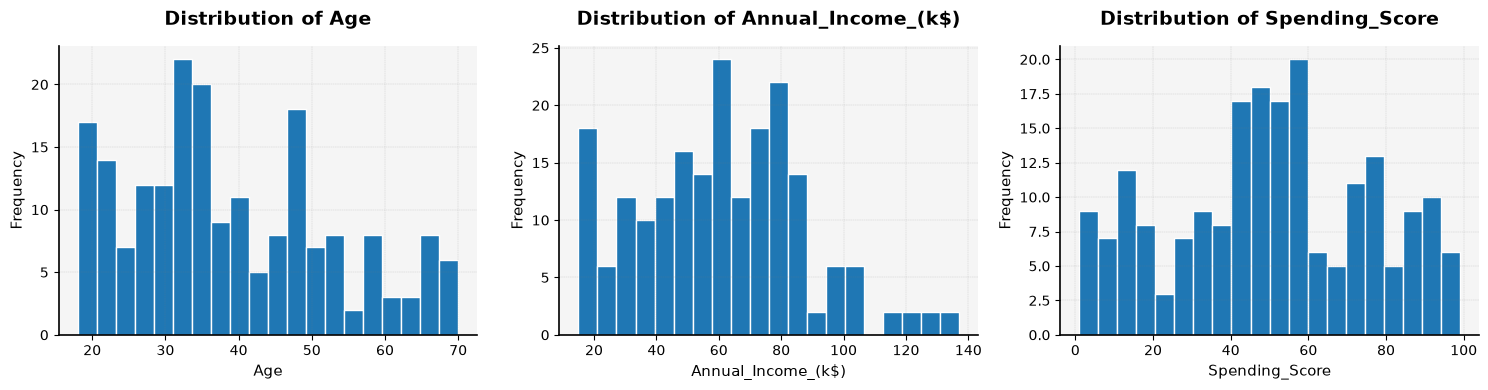

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, feature_columns):
    ax.hist(X[col], bins=20, edgecolor="white")
    style_plot(ax, title=f"Distribution of {col}",
               xlabel=col, ylabel="Frequency", legend=False)
plt.tight_layout()
plt.show()


## **Interpretation of the Exploratory Data Analysis**

The exploratory analysis provides an initial understanding of the demographic and spending characteristics of customers in the Mall Customers dataset.

### **1. Distribution of Age**

Customer ages range approximately from 18 to 70 years. The distribution shows noticeable concentrations around the early 30s (approximately 32–34 years) and late 40s (approximately 48–50 years).

This suggests that the dataset contains customers from different age groups, with relatively strong representation in these two age ranges. Age may therefore contribute to identifying customer segments with different demographic characteristics.

### **2. Distribution of Annual Income**

Annual income ranges approximately from $15,000 to $140,000, with most customers concentrated between $40,000 and $80,000. The distribution appears broadly bell-shaped, with a noticeable concentration around $60,000.

This indicates variation in customers' purchasing power. Annual income may help distinguish customers with different spending capacities.

### **3. Distribution of Spending Score**

Spending scores range from 1 to 100, with a relatively broad distribution and a noticeable concentration between 40 and 60.

Unlike annual income, which provides an indication of purchasing capacity, spending score reflects customers' spending behaviour. This feature may be particularly useful for identifying groups with different spending patterns.

### **Overall EDA Conclusion**

The three features exhibit different distributions and represent complementary aspects of customer characteristics:

- **Age:** Provides demographic information.
- **Annual Income:** Represents customers' income levels.
- **Spending Score:** Provides an indication of customer spending behaviour.

The observed variation suggests that the dataset is suitable for exploring customer segments using K-Means and hierarchical clustering.

Modelling consideration: Since these variables have different measurement scales, standardisation using `StandardScaler` is necessary before applying distance-based clustering algorithms. Also, the EDA provides preliminary insights; the actual customer segments should be determined from the clustering results rather than assumed from the histograms.

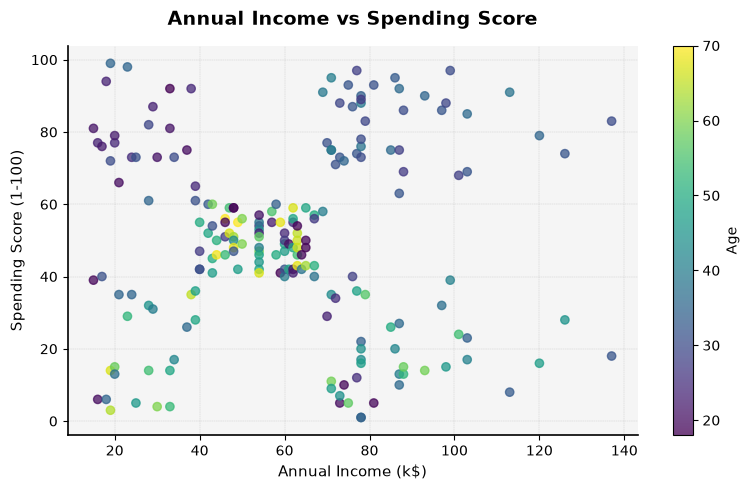

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(X["Annual_Income_(k$)"],
                X["Spending_Score"],
                c=X["Age"], cmap="viridis", alpha=0.75)
fig.colorbar(sc, ax=ax, label="Age")
style_plot(ax, title="Annual Income vs Spending Score",
           xlabel="Annual Income (k$)",
           ylabel="Spending Score (1-100)", legend=False)
plt.tight_layout()
plt.show()


## **Insights:**

The scatter plot reveals five potential customer segments based on annual income and spending behaviour, with age represented by colour. These segments provide useful insights into customer characteristics and possible marketing strategies.

### **1. High Income, Low Spending — Conservative High Earners**

- These customers have relatively high annual incomes (approximately $70k–$140k) but low spending scores (0–40).
- They have considerable purchasing power but demonstrate relatively conservative spending behaviour. The variation in marker colours suggests that this segment includes customers from different age groups.

**Business implication:** Target these customers with personalised promotions, premium product recommendations, and loyalty incentives to encourage greater engagement.

### **2. High Income, High Spending — Premium Customers**

- This segment occupies the upper-right region, with annual incomes of approximately $70k–$105k and spending scores between 60 and 100.
- These customers combine relatively high purchasing power with strong spending behaviour, making them potentially valuable customers.

**Business implication:** Focus on customer retention, exclusive offers, premium services, and personalised experiences.

### **3. Middle Income, Moderate Spending — Average Shoppers**

- These customers are concentrated around annual incomes of $40k–$70k and spending scores of 40–60.
- They represent customers with moderate income levels and relatively average spending behaviour.

**Business implication:** Use targeted promotions, product recommendations, and loyalty programmes to encourage increased customer engagement.

### **4. Low Income, High Spending — High-Engagement Lower-Income Customers**

- These customers have annual incomes of approximately $15k–$40k but relatively high spending scores (60–100).
- Despite their lower income levels, they demonstrate strong spending behaviour.

**Business implication:** Consider affordable product bundles, promotional campaigns, and flexible pricing strategies to maintain their engagement.

### **5. Low Income, Low Spending — Budget-Conscious Customers**

- This segment occupies the lower-left region, with annual incomes of approximately $15k–$40k and spending scores between 0 and 40.
- These customers have relatively limited purchasing power and low spending scores.

**Business implication:** Offer value-oriented products, discounts, and affordable packages that align with their likely spending capacity.

## **Conclusion**

The scatter plot suggests that customers differ not only in their income levels but also in how they spend. In particular, annual income does not necessarily determine spending behaviour: some lower-income customers have high spending scores, while some higher-income customers spend relatively little.

This highlights the importance of considering multiple customer characteristics when developing segmentation strategies.

**Key takeaway:** Annual income and spending score provide complementary information for identifying customer groups. However, these five visual groupings are preliminary observations from the scatter plot, not necessarily the final clusters produced by K-Means or hierarchical clustering. Age may provide additional information when interpreting the resulting segments.

## **Connection to the clustering algorithms**

- **K-Means:** Attempts to identify groups by minimising the within-cluster sum of squared distances between observations and their assigned centroids.
- **Hierarchical clustering:** Builds a hierarchy of customer groups, which can be examined using a dendrogram to determine an appropriate number of clusters.

For a fair comparison, use the same standardised features and compare the resulting cluster structures using the silhouette score and Davies–Bouldin index.

## **6. Standardise the features**

K-Means and common hierarchical methods use distances. A variable with a larger numerical scale can dominate those distances. StandardScaler transforms each feature to have approximately zero mean and unit standard deviation.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled, columns=feature_columns, index=X.index
)
display(X_scaled_df.head())

,Age,Annual_Income_(k$),Spending_Score
CustomerID,,,
1,-1.425,-1.739,-0.435
2,-1.281,-1.739,1.196
3,-1.353,-1.701,-1.716
4,-1.138,-1.701,1.040
5,-0.563,-1.663,-0.396


## **7. K-Means clustering**

K-Means partitions observations into a specified number of clusters, $(k)$. It repeatedly assigns each observation to its nearest centroid and recalculates centroids as the means of assigned observations.

**Key points:** K-Means requires $(k)$ in advance, is sensitive to scaling and initialisation, and minimises within-cluster sum of squared distances (inertia).

### **7.1 Elbow method**

Inertia usually decreases as the number of clusters increases. The elbow heuristic looks for a point after which adding clusters produces smaller improvements.

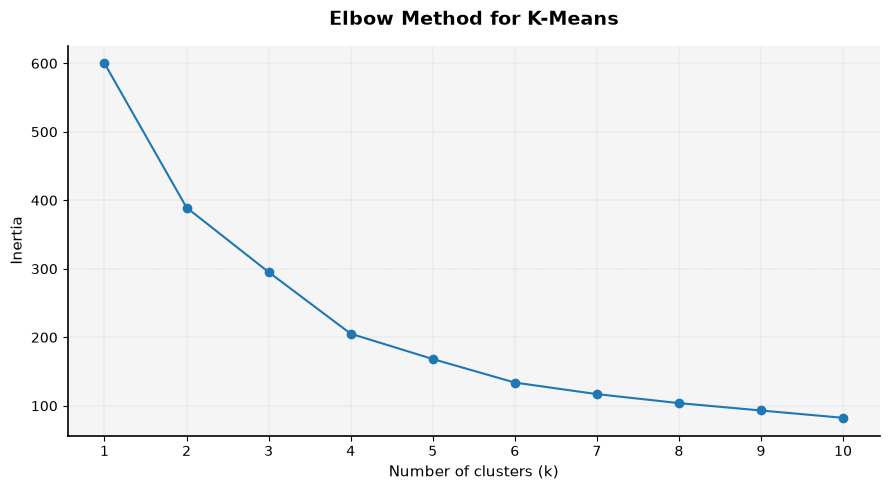

In [32]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(k_values), inertias, marker="o")
ax.set_xticks(list(k_values))
style_plot(ax, title="Elbow Method for K-Means",
           xlabel="Number of clusters (k)", ylabel="Inertia",
           legend=False)
plt.tight_layout()
plt.show()


### **7.2 Evaluate candidate values of k**

- **Silhouette score:** ranges from −1 to 1; higher values generally indicate better-defined clusters.
- **Davies–Bouldin index:** lower values generally indicate more compact, separated clusters.

Use these metrics alongside the elbow plot and interpretability; neither metric alone guarantees the best solution.

In [21]:
metric_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    metric_rows.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels)
    })

kmeans_metrics = pd.DataFrame(metric_rows)
display(kmeans_metrics.round(4))


,k,Inertia,Silhouette Score,Davies-Bouldin Index
0,2,389.386,0.336,1.261
1,3,295.212,0.358,1.050
2,4,205.225,0.404,0.931
3,5,168.248,0.417,0.875
4,6,133.868,0.428,0.825
5,7,117.012,0.417,0.793
6,8,103.873,0.408,0.892
7,9,93.093,0.418,0.820
8,10,82.385,0.407,0.868


### **7.3 Fit K-Means**

The value `5` is used as an initial candidate for this dataset. Inspect your elbow plot and metrics before deciding whether to retain it.

In [24]:
chosen_k = 5

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_dbi = davies_bouldin_score(X_scaled, kmeans_labels)

print(f"Silhouette Score: {kmeans_silhouette:.4f}")
print(f"Davies-Bouldin Index: {kmeans_dbi:.4f}")


Silhouette Score: 0.4166
Davies-Bouldin Index: 0.8746


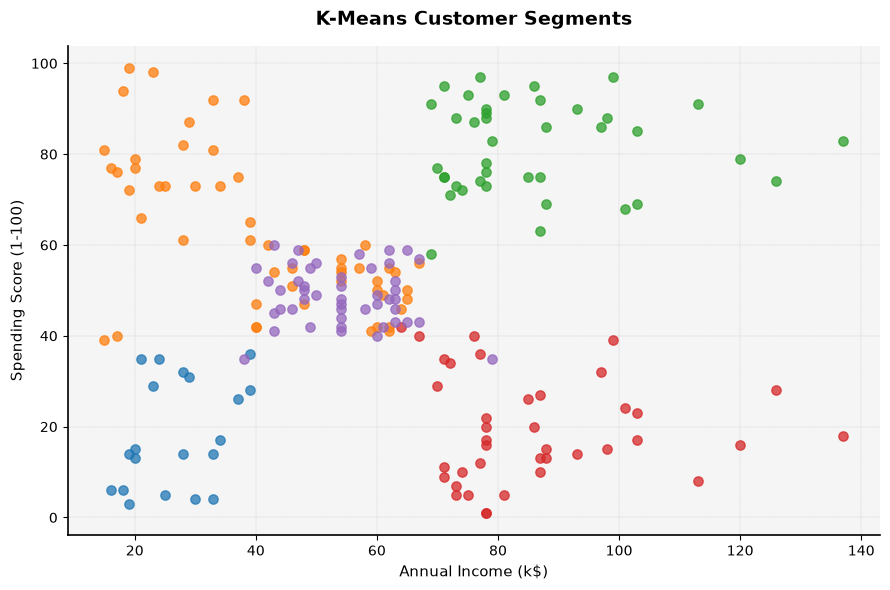

In [26]:
kmeans_results = profile_data.copy()
kmeans_results["KMeans_Cluster"] = kmeans_labels

fig, ax = plt.subplots(figsize=(9, 6))
for cluster in sorted(kmeans_results["KMeans_Cluster"].unique()):
    part = kmeans_results[kmeans_results["KMeans_Cluster"] == cluster]
    ax.scatter(part["Annual_Income_(k$)"],
               part["Spending_Score"],
               label=f"Cluster {cluster}", alpha=0.75, s=45)

style_plot(ax, title="K-Means Customer Segments",
           xlabel="Annual Income (k$)",
           ylabel="Spending Score (1-100)")
plt.tight_layout()
plt.show()


## **8. Hierarchical clustering**

Agglomerative hierarchical clustering is a bottom-up procedure:

1. Begin with each observation as an individual cluster.
2. Merge the two closest clusters.
3. Repeat until the desired number of clusters is reached.

Common linkage methods:
- **Single:** minimum pairwise distance between two clusters.
- **Complete:** maximum pairwise distance.
- **Average:** average pairwise distance.
- **Ward:** merges clusters to minimise the increase in within-cluster variance. Ward is used with Euclidean distance.

A dendrogram displays the hierarchical merging process.

### **8.1 Dendrogram**

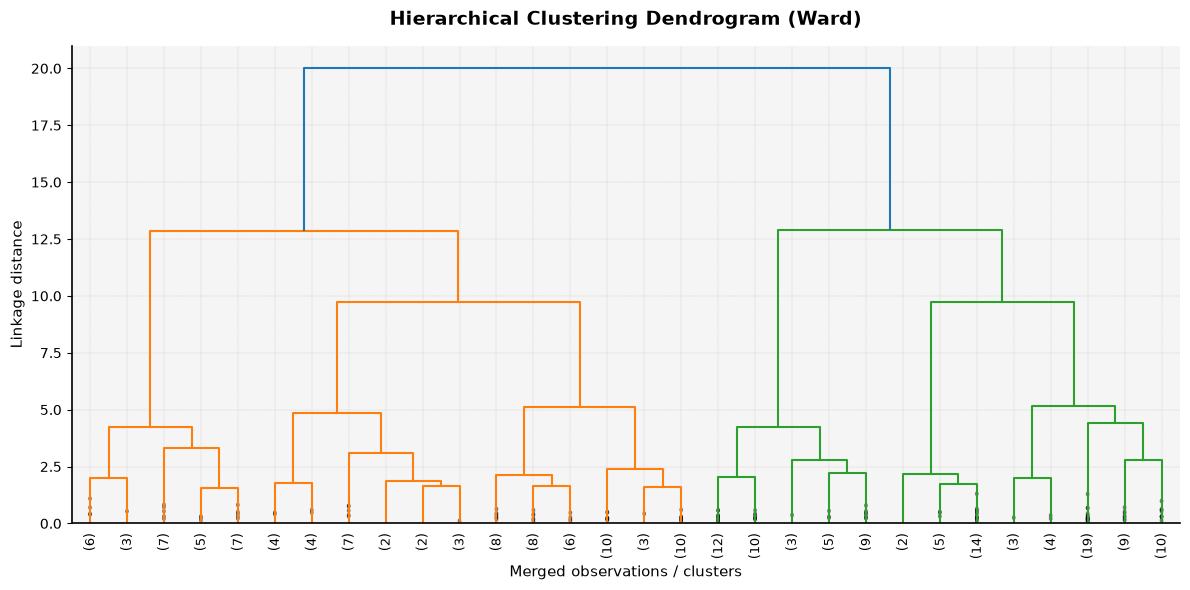

In [22]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(
    Z, truncate_mode="lastp", p=30,
    leaf_rotation=90, leaf_font_size=9,
    show_contracted=True, ax=ax
)
style_plot(ax, title="Hierarchical Clustering Dendrogram (Ward)",
           xlabel="Merged observations / clusters",
           ylabel="Linkage distance", legend=False)
plt.tight_layout()
plt.show()


### **8.2 Fit agglomerative clustering**

We use the same `chosen_k` to make a straightforward comparison with K-Means.

In [27]:
hierarchical = AgglomerativeClustering(
    n_clusters=chosen_k,
    metric="euclidean",
    linkage="ward"
)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

hierarchical_silhouette = silhouette_score(X_scaled, hierarchical_labels)
hierarchical_dbi = davies_bouldin_score(X_scaled, hierarchical_labels)

print(f"Silhouette Score: {hierarchical_silhouette:.4f}")
print(f"Davies-Bouldin Index: {hierarchical_dbi:.4f}")


Silhouette Score: 0.3900
Davies-Bouldin Index: 0.9163


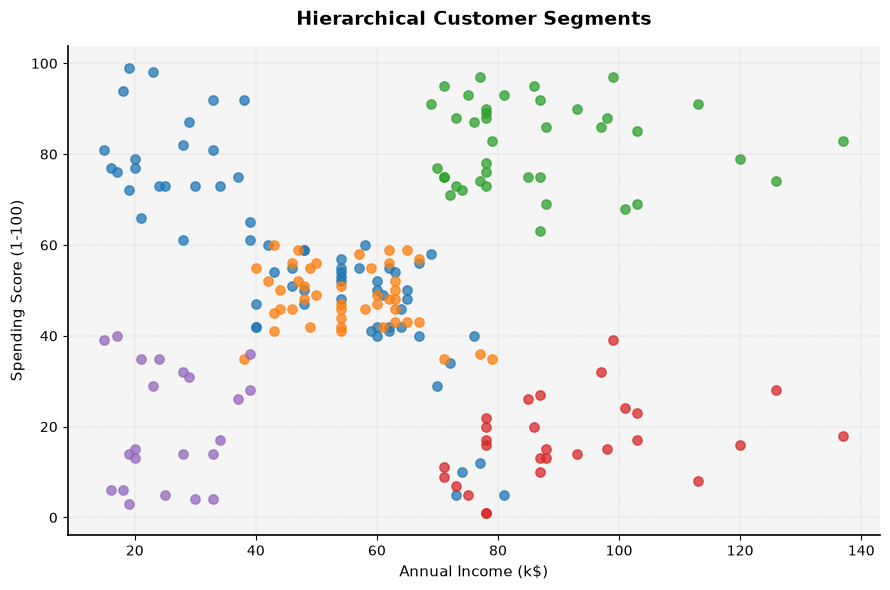

In [29]:
hierarchical_results = profile_data.copy()
hierarchical_results["Hierarchical_Cluster"] = hierarchical_labels

fig, ax = plt.subplots(figsize=(9, 6))
for cluster in sorted(hierarchical_results["Hierarchical_Cluster"].unique()):
    part = hierarchical_results[
        hierarchical_results["Hierarchical_Cluster"] == cluster
    ]
    ax.scatter(part["Annual_Income_(k$)"],
               part["Spending_Score"],
               label=f"Cluster {cluster}", alpha=0.75, s=45)

style_plot(ax, title="Hierarchical Customer Segments",
           xlabel="Annual Income (k$)",
           ylabel="Spending Score (1-100)")
plt.tight_layout()
plt.show()


## **9. Compare the methods**

Cluster numbers are arbitrary identifiers. Cluster 0 from K-Means is not necessarily the same group as cluster 0 from hierarchical clustering.

In [30]:
comparison = pd.DataFrame({
    "Method": ["K-Means", "Agglomerative (Ward)"],
    "Silhouette Score": [kmeans_silhouette, hierarchical_silhouette],
    "Davies-Bouldin Index": [kmeans_dbi, hierarchical_dbi]
})
display(comparison.round(4))


,Method,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.417,0.875
1,Agglomerative (Ward),0.390,0.916


## **10. Interpret cluster profiles**

Summarise the original features to understand how the resulting groups differ. Avoid assigning marketing labels before inspecting these statistics.

In [31]:
kmeans_profile = (
    kmeans_results
    .groupby("KMeans_Cluster")[feature_columns]
    .agg(["count", "mean", "median"])
)
display(kmeans_profile.round(2))

if "Gender" in kmeans_results.columns:
    display(pd.crosstab(
        kmeans_results["KMeans_Cluster"],
        kmeans_results["Gender"],
        normalize="index"
    ).round(3))


Age               Annual_Income_(k$)                \
               count   mean median              count   mean median   
KMeans_Cluster                                                        
0                 20 46.250 47.000                 20 26.750 26.500   
1                 54 25.190 24.000                 54 41.090 40.000   
2                 40 32.880 32.000                 40 86.100 78.500   
3                 39 39.870 41.000                 39 86.100 78.000   
4                 47 55.640 54.000                 47 54.380 54.000   

               Spending_Score                
                        count   mean median  
KMeans_Cluster                               
0                          20 18.350 14.500  
1                          54 62.240 58.000  
2                          40 81.530 83.000  
3                          39 19.360 17.000  
4                          47 48.850 48.000

## 11. Key concepts summary

| K-Means | Hierarchical clustering |
|---|---|
| Requires the number of clusters, \(k\), in advance | Dendrogram helps explore possible cuts |
| Uses centroids | Builds a hierarchy of merged clusters |
| Iteratively assigns points and updates centroids | Agglomerative method repeatedly merges clusters |
| Sensitive to initialisation and outliers | Sensitive to distance and linkage choices |
| Often practical for larger datasets | Can be computationally expensive on large datasets |

**Exam reminders**
- K-Means minimises within-cluster sum of squared distances.
- The elbow method is a heuristic for choosing \(k\).
- Higher silhouette is generally better.
- Lower Davies–Bouldin index is generally better.
- Ward linkage minimises the increase in within-cluster variance at each merge.
- Standardisation matters when features have different scales.
- Cluster labels have no inherent ranking.
- Clustering is unsupervised: it does not require a target variable.


## **12. Multiple-choice questions (MCQs)**

### **Question 1**
What is the primary purpose of clustering?

- A. Predict a continuous target
- B. Group observations by similarity
- C. Estimate causal effects
- D. Assign known class labels


__Answer: B__

- Clustering groups observations based on a similarity or distance measure without requiring known labels.

### **Question 2**
K-Means is best described as:

- A. A supervised classifier
- B. A density estimator
- C. A centroid-based partitioning algorithm
- D. A dimensionality-reduction method

__Answer: C__
- K-Means represents each cluster by a centroid and assigns observations to the nearest centroid.

### **Question 3**
In K-Means, k represents:

- A. Number of features
- B. Number of observations
- C. Number of clusters
- D. Number of labels

__Answer: C__

- Explanation': 'The user specifies the number of clusters, k.

### **Question 4**
What does standard K-Means seek to minimise?

- A. Within-cluster sum of squared distances
- B. Number of clusters
- C. Number of features
- D. Classification error

__Answer:  A__

- Explanation: K-Means minimises the sum of squared distances from observations to their assigned centroids.

### **Question 5**
The elbow method is commonly used to:

- A. Choose a scaler
- B. Estimate a suitable number of clusters
- C. Find missing values
- D. Calculate accuracy

__Answer: B__

- Explanation: It examines how inertia changes as k increases and looks for diminishing returns.

### **Question 6**
Why standardise features before distance-based clustering?

- A. To remove all outliers
- B. To make all variables normally distributed
- C. To stop large-scale variables dominating distances
- D. To create target labels


__Answer:   C__

- Explanation: Variables on larger numerical scales can otherwise dominate distance calculations.

### **Question 7**
Which statement about silhouette score is correct?

- A. It ranges from 0 to 100
- B. Higher values generally indicate better-defined clusters
- C. Lower values are always better
- D. It only applies to K-Means

__Answer: B__

- Explanation: A negative silhouette suggests the observation may be closer to another cluster.

### **Question 8**
A strongly negative silhouette value suggests that an observation:

- A. May be assigned to an unsuitable cluster
- B. Is exactly at its centroid
- C. Must be missing
- D. Is always an outlier

__Answer: A__

- Explanation: A negative silhouette suggests the observation may be closer to another cluster.

### **Question 9**
How is the Davies–Bouldin index generally interpreted?

- A. Higher is better
- B. Lower is generally better
- C. It must equal silhouette
- D. It measures prediction accuracy

__Answer:  B__

- Explanation: Lower DBI generally indicates more compact clusters with better separation.

### Question 10
Agglomerative hierarchical clustering begins with:

- A. One cluster containing all observations
- B. A random centroid
- C. Each observation as its own cluster
- D. Known class labels

### Question 11
A dendrogram displays:

- A. Regression coefficients
- B. The sequence and distances of cluster merges
- C. Neural-network loss
- D. Target distributions

### Question 12
Which linkage uses the minimum pairwise distance between two clusters?

- A. Complete
- B. Average
- C. Ward
- D. Single

### Question 13
Which linkage uses the maximum pairwise distance between two clusters?

- A. Complete
- B. Single
- C. Average
- D. Ward

### Question 14
Ward linkage seeks to:

- A. Maximise cluster count
- B. Minimise the increase in within-cluster variance at each merge
- C. Maximise within-cluster distances
- D. Merge the largest observations

### Question 15
Which statement about cluster labels is true?

- A. Cluster 0 is always smallest
- B. Cluster 1 is always best
- C. Cluster numbers are arbitrary identifiers
- D. Labels match across algorithms

### Question 16
Why exclude CustomerID from the feature matrix?

- A. It is always missing
- B. It is an identifier, not a customer similarity measure
- C. It is a target variable
- D. K-Means accepts only text

### Question 17
Which is an unsupervised learning task?

- A. Predict churn from labelled outcomes
- B. Predict house prices
- C. Group customers without known labels
- D. Classify labelled emails

### Question 18
A common limitation of K-Means is that it:

- A. Cannot calculate distances
- B. Requires k and can be sensitive to initialisation and outliers
- C. Always finds the same solution
- D. Only works with binary features

### Question 19
Two features are measured in dollars and years. A sensible step before distance-based clustering is to:

- A. Standardise the features
- B. Convert all values to strings
- C. Delete the smaller-scale feature
- D. Sort rows alphabetically

__Answer: A__

- Standardisation puts features on comparable scales

### Question 20
What is the most defensible way to choose a clustering solution?

- A. Always choose the largest k
- B. Use only the scatter-plot colours
- C. Consider metrics, interpretability and the analysis objective
- D. Choose the method with most clusters

__Answer:  C__

- A defensible choice combines quantitative diagnostics with substantive interpretation

## 13. Answer key with explanations

Use this section after attempting all 20 questions.

In [ ]:
answer_key = pd.DataFrame([{'Question': 1, 'Correct answer': 'B', 'Explanation': ''}, {'Question': 2, 'Correct answer': 'C', 'Explanation': 'K-Means represents each cluster by a centroid and assigns observations to the nearest centroid.'}, {'Question': 3, 'Correct answer': 'C', 'Explanation': 'The user specifies the number of clusters, k.'}, {'Question': 4, 'Correct answer': 'A', 'Explanation': 'K-Means minimises the sum of squared distances from observations to their assigned centroids.'}, {'Question': 5, 'Correct answer': 'B', 'Explanation': 'It examines how inertia changes as k increases and looks for diminishing returns.'}, {'Question': 6, 'Correct answer': 'C', 'Explanation': 'Variables on larger numerical scales can otherwise dominate distance calculations.'}, {'Question': 7, 'Correct answer': 'B', 'Explanation': 'Silhouette ranges from −1 to 1; higher values generally indicate stronger cohesion and separation.'}, {'Question': 8, 'Correct answer': 'A', 'Explanation': 'A negative silhouette suggests the observation may be closer to another cluster.'}, {'Question': 9, 'Correct answer': 'B', 'Explanation': 'Lower DBI generally indicates more compact clusters with better separation.'}, {'Question': 10, 'Correct answer': 'C', 'Explanation': 'Agglomerative clustering is bottom-up: each observation starts in its own cluster.'}, {'Question': 11, 'Correct answer': 'B', 'Explanation': 'A dendrogram visualises hierarchical merges and their linkage distances.'}, {'Question': 12, 'Correct answer': 'D', 'Explanation': 'Single linkage defines the distance between clusters as the minimum pairwise distance.'}, {'Question': 13, 'Correct answer': 'A', 'Explanation': 'Complete linkage uses the maximum pairwise distance.'}, {'Question': 14, 'Correct answer': 'B', 'Explanation': "Ward's criterion chooses the merge that produces the smallest increase in within-cluster variance."}, {'Question': 15, 'Correct answer': 'C', 'Explanation': 'Cluster labels have no inherent order and need not match between algorithms.'}, {'Question': 16, 'Correct answer': 'B', 'Explanation': 'The numeric value of an identifier generally has no meaningful relationship to customer similarity.'}, {'Question': 17, 'Correct answer': 'C', 'Explanation': 'Clustering discovers groups without a known target label.'}, {'Question': 18, 'Correct answer': 'B', 'Explanation': 'K-Means requires k in advance and can be affected by centroid initialisation and extreme observations.'}, {'Question': 19, 'Correct answer': 'A', 'Explanation': 'Standardisation puts features on comparable scales.'}, {'Question': 20, 'Correct answer': 'C', 'Explanation': 'A defensible choice combines quantitative diagnostics with substantive interpretation.'}])
display(answer_key)

,Question,Correct answer,Explanation
0,1,B,Clustering groups observations based on a simi...
1,2,C,K-Means represents each cluster by a centroid ...
2,3,C,"The user specifies the number of clusters, k."
3,4,A,K-Means minimises the sum of squared distances...
4,5,B,It examines how inertia changes as k increases...
5,6,C,Variables on larger numerical scales can other...
6,7,B,Silhouette ranges from −1 to 1; higher values ...
7,8,A,A negative silhouette suggests the observation...
8,9,B,Lower DBI generally indicates more compact clu...
9,10,C,Agglomerative clustering is bottom-up: each ob...
